<a href="https://colab.research.google.com/github/cs23f016/CSL701_CS25_Machine-Learning-Lab/blob/main/Copy_of_ML_Experiment_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  ML Experiment Number 9
Student Name :Ganesh Shankar Khadapkar

Batch :CS2


Roll Number :CS25



### **Aim**

To implement Classification and Regression Trees (CART) using Python on the Palmer Penguins Dataset Extended.

## Objectives

1. To understand the concept and working of the CART algorithm.
2. To implement Decision Tree Classification using Python.   
3. To visualize the constructed Decision Tree structure and decision boundaries.   
4. To analyze impurity measures such as Gini Index and Entropy.
5. To compare the decision boundary of a Decision Tree with a linear classification boundary (e.g., Logistic Regression).   
6. To evaluate and compare the performance of both classifiers.

# Relevant Theory

###Classification and Regression Trees (CART)
CART is a non-parametric supervised machine learning algorithm used for both classification and regression tasks. It builds a binary decision tree by recursively splitting the dataset based on feature values that maximize information gain or minimize impurity.

A tree consists of:

* Root Node: The topmost node representing the entire dataset.

* Internal Nodes: Decision points based on feature splits.

* Leaf/Terminal Nodes: Output class labels or predictions.

Impurity MeasuresGini Index (Gini Impurity): Measures the frequency with which a randomly chosen element from the set would be incorrectly labeled.$$Gini(D) = 1 - \sum_{i=1}^{k} p_i^2$$where $p_i$ is the probability of an item belonging to class $i$.Entropy & Information Gain: Measures the amount of impurity or randomness in the data.$$Entropy(D) = -\sum_{i=1}^{k} p_i \log_2(p_i)$$Dataset InformationGet the Palmer Penguins Dataset Extended from Kaggle using the following link:https://www.kaggle.com/datasets/samybaladram/palmers-penguin-dataset-extended The Palmer Penguins dataset contains measurements of penguin species across islands in the Palmer Archipelago:AdelieChinstrapGentooThe primary numerical features are:culmen_length_mm (or bill_length_mm)culmen_depth_mm (or bill_depth_mm)flipper_length_mmbody_mass_gFor visualization, we will use: culmen_length_mm and flipper_length_mm.

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Palmer Penguins Extended dataset.
---

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

from IPython.display import display
import ipywidgets as widgets
from IPython.display import clear_output

upload = widgets.FileUpload(
    accept='.csv',
    multiple=False
)

display(upload)

FileUpload(value={}, accept='.csv', description='Upload')

In [7]:
if not upload.value:
    print("Please upload your CSV file first.")
else:
    uploaded_file = upload.value

    if isinstance(uploaded_file, dict):
        file_name = list(uploaded_file.keys())[0]
        file_content = uploaded_file[file_name]["content"]
    else:
        file_info = uploaded_file[0]
        file_name = file_info["name"]
        file_content = file_info["content"]

    import io

    df = pd.read_csv(io.BytesIO(file_content))

    print("Dataset loaded successfully!")
    print("File:", file_name)
    print("Shape:", df.shape)
    print("\nFirst five rows:")
    display(df.head())

    print("\nColumn names:")
    print(df.columns.tolist())

Dataset loaded successfully!
File: palmerpenguins_extended.csv
Shape: (3430, 11)

First five rows:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,diet,life_stage,health_metrics,year
0,Adelie,Biscoe,53.4,17.8,219.0,5687.0,female,fish,adult,overweight,2021
1,Adelie,Biscoe,49.3,18.1,245.0,6811.0,female,fish,adult,overweight,2021
2,Adelie,Biscoe,55.7,16.6,226.0,5388.0,female,fish,adult,overweight,2021
3,Adelie,Biscoe,38.0,15.6,221.0,6262.0,female,fish,adult,overweight,2021
4,Adelie,Biscoe,60.7,17.9,177.0,4811.0,female,fish,juvenile,overweight,2021



Column names:
['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex', 'diet', 'life_stage', 'health_metrics', 'year']


# Task 2: Select Features and Target & Preprocess

* Handle missing values (e.g., drop rows with missing values or impute with median).   
* Select features ($X$) such as culmen_length_mm, culmen_depth_mm, flipper_length_mm, body_mass_g and set species as the target label ($y$).   
* Encode categorical targets if necessary using LabelEncoder.

In [8]:
df.columns = df.columns.str.strip().str.lower()

def find_column(options):
    for col in options:
        if col in df.columns:
            return col
    return None

species_col = find_column(["species"])
length_col = find_column(["culmen_length_mm", "bill_length_mm"])
depth_col = find_column(["culmen_depth_mm", "bill_depth_mm"])
flipper_col = find_column(["flipper_length_mm"])
mass_col = find_column(["body_mass_g"])

required = {
    "species": species_col,
    "culmen length": length_col,
    "culmen depth": depth_col,
    "flipper length": flipper_col,
    "body mass": mass_col
}

missing = [name for name, col in required.items() if col is None]

if missing:
    raise ValueError(
        f"Missing columns: {missing}\n"
        f"Available columns: {df.columns.tolist()}"
    )

data = df[
    [species_col, length_col, depth_col, flipper_col, mass_col]
].copy()

data.columns = [
    "species",
    "culmen_length_mm",
    "culmen_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

data = data.dropna()
data = data[data["species"].isin(["Adelie", "Chinstrap", "Gentoo"])]

X = data[
    ["culmen_length_mm", "culmen_depth_mm",
     "flipper_length_mm", "body_mass_g"]
]

encoder = LabelEncoder()
y = encoder.fit_transform(data["species"])

print("Features selected successfully.")
print("Species classes:", list(encoder.classes_))
print("Dataset shape after preprocessing:", data.shape)
print(data.head())

Features selected successfully.
Species classes: ['Adelie', 'Chinstrap', 'Gentoo']
Dataset shape after preprocessing: (3430, 5)
  species  culmen_length_mm  culmen_depth_mm  flipper_length_mm  body_mass_g
0  Adelie              53.4             17.8              219.0       5687.0
1  Adelie              49.3             18.1              245.0       6811.0
2  Adelie              55.7             16.6              226.0       5388.0
3  Adelie              38.0             15.6              221.0       6262.0
4  Adelie              60.7             17.9              177.0       4811.0


# Task 3: Split the Data

* Divide the dataset into training and testing sets using train_test_split.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 2744
Testing samples: 686


# Task 4: Implement CART Classifier

* Create a DecisionTreeClassifier model using the Gini criterion (or Entropy).   
* Fit the model on the training data and make predictions on the test set.   

In [10]:
cart_model = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

cart_model.fit(X_train, y_train)
y_pred_cart = cart_model.predict(X_test)

print("CART classifier trained successfully!")

CART classifier trained successfully!


# Task 5: Evaluate CART Model

* Accuracy: Calculate classification accuracy.   
* Confusion Matrix: Generate the matrix to analyze misclassifications across species.
* Classification Report: Output Precision, Recall, F1-Score, and Support.   

In [11]:
print("CART Accuracy:",
      accuracy_score(y_test, y_pred_cart))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_cart))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_cart,
    labels=np.arange(len(encoder.classes_)),
    target_names=encoder.classes_,
    zero_division=0
))

CART Accuracy: 0.4518950437317784

Confusion Matrix:
[[155  64  93]
 [ 48  33  44]
 [ 76  51 122]]

Classification Report:
              precision    recall  f1-score   support

      Adelie       0.56      0.50      0.52       312
   Chinstrap       0.22      0.26      0.24       125
      Gentoo       0.47      0.49      0.48       249

    accuracy                           0.45       686
   macro avg       0.42      0.42      0.42       686
weighted avg       0.46      0.45      0.46       686



# Task 6: Visualize Decision Tree & Decision Boundary

* Visualize Tree Structure: Plot the decision tree diagram using sklearn.tree.plot_tree.
* Select 2-D Features: Select culmen_length_mm and flipper_length_mm.   
* Train 2-D Model & Plot Boundary: Train the decision tree on 2D data and plot axis-aligned rectangular decision boundaries along with data points


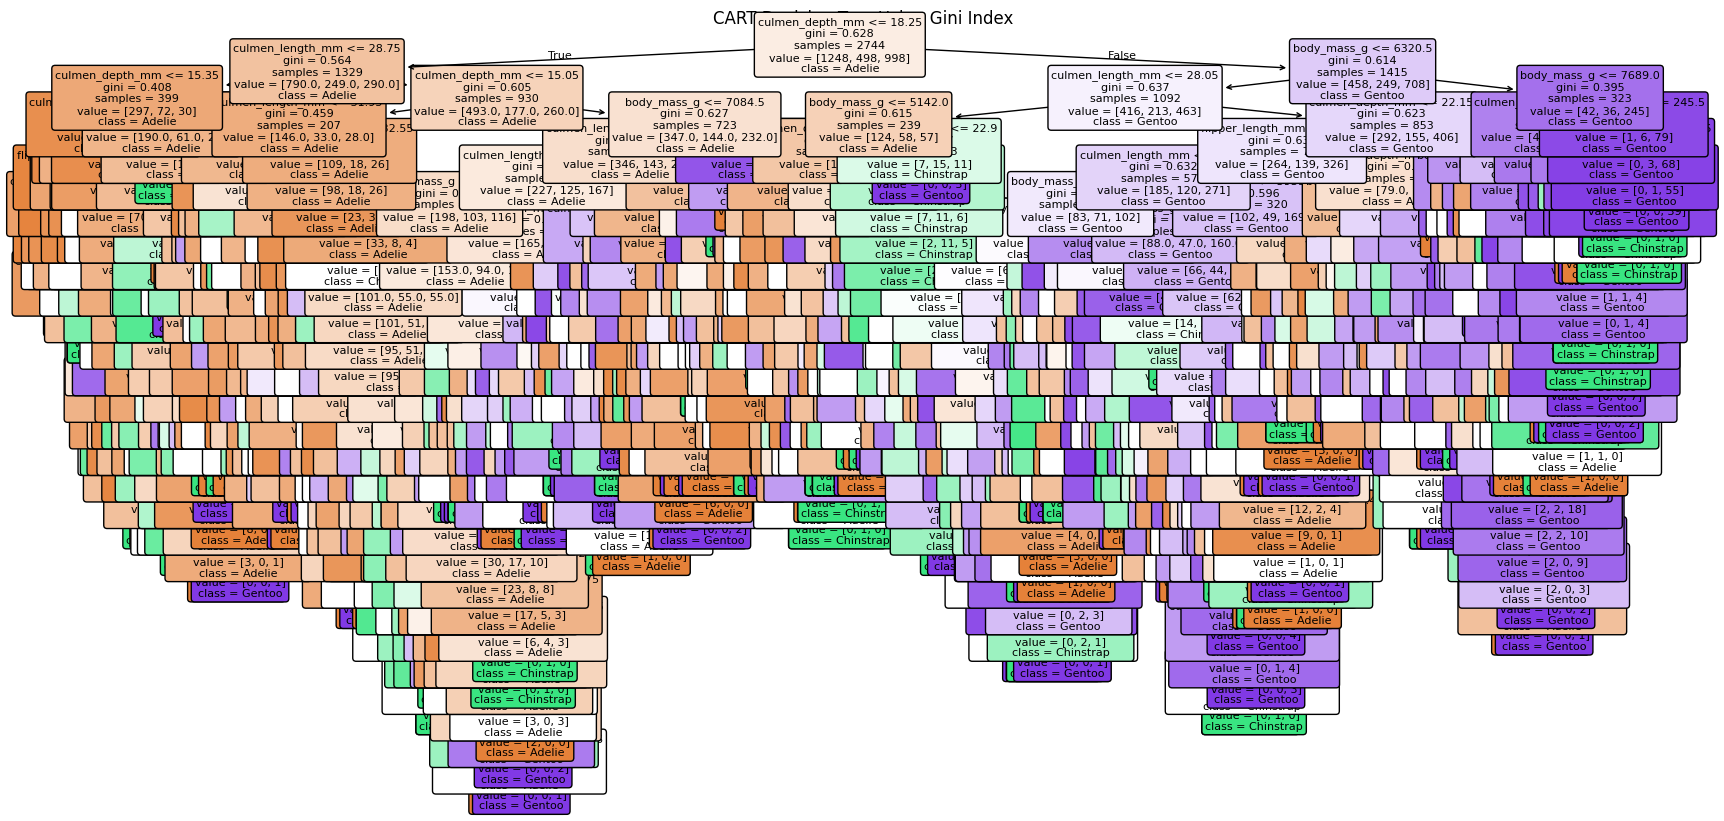

In [12]:
plt.figure(figsize=(20, 10))

plot_tree(
    cart_model,
    feature_names=X.columns,
    class_names=encoder.classes_,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("CART Decision Tree Using Gini Index")
plt.show()

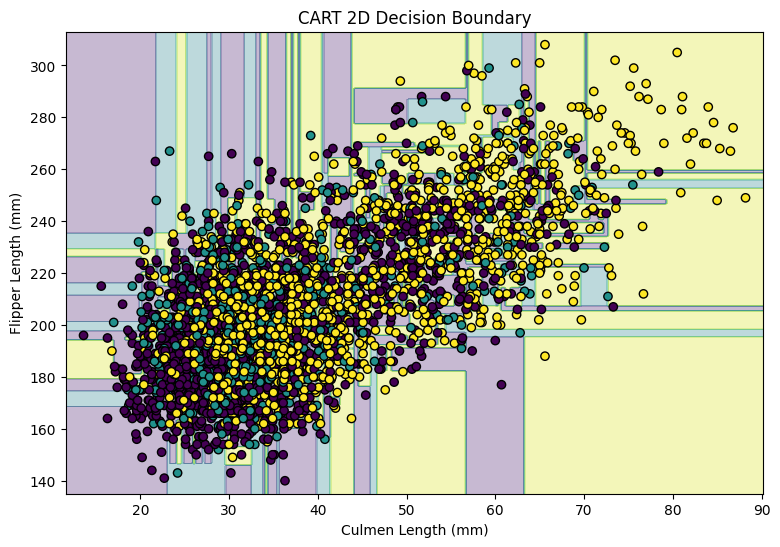

In [14]:
features_2d = ["culmen_length_mm", "flipper_length_mm"]
X_2d = data[features_2d]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X_2d, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

tree_2d = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

tree_2d.fit(X2_train, y2_train)

x_min = X_2d.iloc[:, 0].min() - 2
x_max = X_2d.iloc[:, 0].max() + 2
y_min = X_2d.iloc[:, 1].min() - 5
y_max = X_2d.iloc[:, 1].max() + 5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = pd.DataFrame(
    np.c_[xx.ravel(), yy.ravel()],
    columns=features_2d
)

Z = tree_2d.predict(grid).reshape(xx.shape)

plt.figure(figsize=(9, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap="viridis")
plt.scatter(
    X_2d.iloc[:, 0],
    X_2d.iloc[:, 1],
    c=y,
    cmap="viridis",
    edgecolors="black"
)

plt.xlabel("Culmen Length (mm)")
plt.ylabel("Flipper Length (mm)")
plt.title("CART 2D Decision Boundary")
plt.show()

# Task 7: Normal Linear Classification Boundary

* Train a Logistic Regression model using the same two features as a normal linear baseline.   
* Visualize its linear decision boundary.

In [15]:
scaler = StandardScaler()

X2_train_scaled = scaler.fit_transform(X2_train)
X2_test_scaled = scaler.transform(X2_test)

log_model = LogisticRegression(max_iter=1000)
log_model.fit(X2_train_scaled, y2_train)

y_pred_log = log_model.predict(X2_test_scaled)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


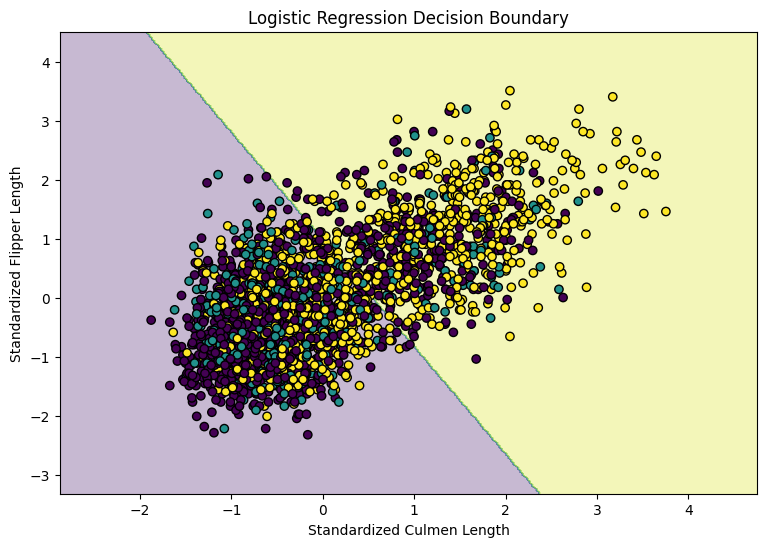

In [16]:
xx_s, yy_s = np.meshgrid(
    np.linspace(X2_train_scaled[:, 0].min() - 1,
                X2_train_scaled[:, 0].max() + 1, 300),
    np.linspace(X2_train_scaled[:, 1].min() - 1,
                X2_train_scaled[:, 1].max() + 1, 300)
)

grid_scaled = np.c_[xx_s.ravel(), yy_s.ravel()]
Z_log = log_model.predict(grid_scaled).reshape(xx_s.shape)

plt.figure(figsize=(9, 6))
plt.contourf(xx_s, yy_s, Z_log, alpha=0.3, cmap="viridis")
plt.scatter(
    X2_train_scaled[:, 0],
    X2_train_scaled[:, 1],
    c=y2_train,
    cmap="viridis",
    edgecolors="black"
)

plt.xlabel("Standardized Culmen Length")
plt.ylabel("Standardized Flipper Length")
plt.title("Logistic Regression Decision Boundary")
plt.show()

# Task 8: Compare CART and Normal Linear Boundary

* Plot both the Decision Tree (axis-aligned non-linear) and Logistic Regression (linear) decision boundaries on side-by-side subplots.   * Compare how non-linear CART boundaries differ from straight linear hyperplanes.

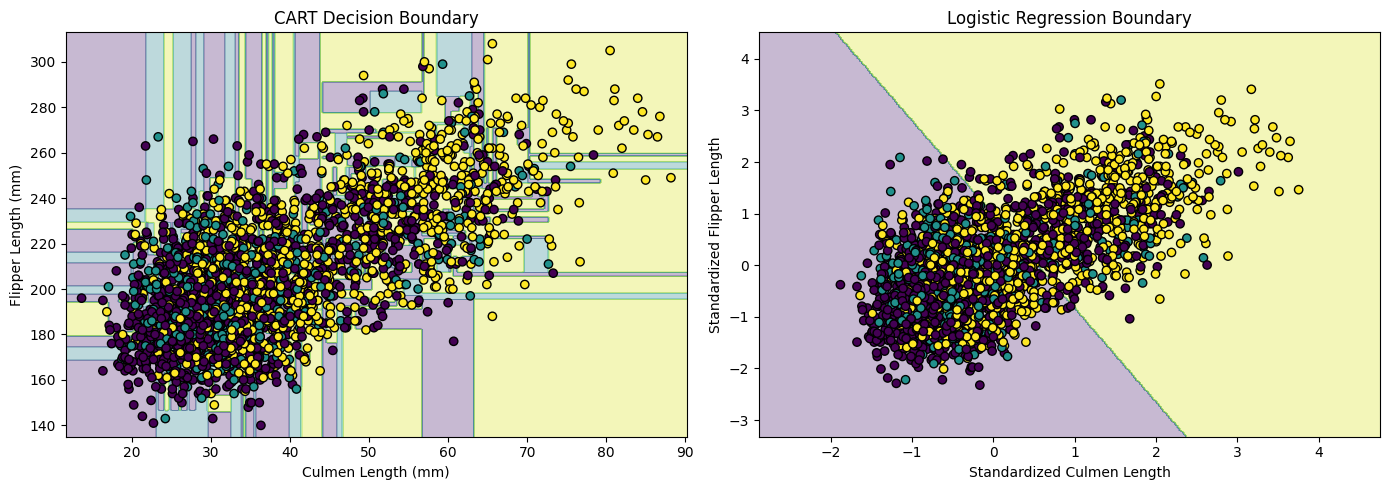

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# CART
axes[0].contourf(xx, yy, Z, alpha=0.3, cmap="viridis")
axes[0].scatter(
    X2_train.iloc[:, 0],
    X2_train.iloc[:, 1],
    c=y2_train,
    cmap="viridis",
    edgecolors="black"
)
axes[0].set_xlabel("Culmen Length (mm)")
axes[0].set_ylabel("Flipper Length (mm)")
axes[0].set_title("CART Decision Boundary")

# Logistic Regression
axes[1].contourf(xx_s, yy_s, Z_log, alpha=0.3, cmap="viridis")
axes[1].scatter(
    X2_train_scaled[:, 0],
    X2_train_scaled[:, 1],
    c=y2_train,
    cmap="viridis",
    edgecolors="black"
)
axes[1].set_xlabel("Standardized Culmen Length")
axes[1].set_ylabel("Standardized Flipper Length")
axes[1].set_title("Logistic Regression Boundary")

plt.tight_layout()
plt.show()

# Task 9: Compare Performance

* Compare the evaluation metrics (Accuracy, Confusion Matrix, Classification Report) of the CART Classifier vs. Logistic Regression.

In [18]:
y_pred_tree = tree_2d.predict(X2_test)
y_pred_log = log_model.predict(X2_test_scaled)

print("========== CART CLASSIFIER ==========")
print("Accuracy:", accuracy_score(y2_test, y_pred_tree))
print("\nConfusion Matrix:")
print(confusion_matrix(y2_test, y_pred_tree))
print("\nClassification Report:")
print(classification_report(
    y2_test, y_pred_tree,
    labels=np.arange(len(encoder.classes_)),
    target_names=encoder.classes_,
    zero_division=0
))

print("\n========== LOGISTIC REGRESSION ==========")
print("Accuracy:", accuracy_score(y2_test, y_pred_log))
print("\nConfusion Matrix:")
print(confusion_matrix(y2_test, y_pred_log))
print("\nClassification Report:")
print(classification_report(
    y2_test, y_pred_log,
    labels=np.arange(len(encoder.classes_)),
    target_names=encoder.classes_,
    zero_division=0
))

========== CART CLASSIFIER ==========
Accuracy: 0.4387755102040816

Confusion Matrix:
[[156  52 104]
 [ 55  31  39]
 [ 83  52 114]]

Classification Report:
              precision    recall  f1-score   support

      Adelie       0.53      0.50      0.51       312
   Chinstrap       0.23      0.25      0.24       125
      Gentoo       0.44      0.46      0.45       249

    accuracy                           0.44       686
   macro avg       0.40      0.40      0.40       686
weighted avg       0.44      0.44      0.44       686


========== LOGISTIC REGRESSION ==========
Accuracy: 0.5262390670553936

Confusion Matrix:
[[245   0  67]
 [102   0  23]
 [133   0 116]]

Classification Report:
              precision    recall  f1-score   support

      Adelie       0.51      0.79      0.62       312
   Chinstrap       0.00      0.00      0.00       125
      Gentoo       0.56      0.47      0.51       249

    accuracy                           0.53       686
   macro avg       0.36      0

In [19]:
comparison = pd.DataFrame({
    "Classifier": ["CART Decision Tree", "Logistic Regression"],
    "Accuracy": [
        accuracy_score(y2_test, y_pred_tree),
        accuracy_score(y2_test, y_pred_log)
    ]
})

print(comparison)

            Classifier  Accuracy
0   CART Decision Tree  0.438776
1  Logistic Regression  0.526239


# Conclusion

The experiment successfully demonstrated the implementation of the Classification and Regression Tree (CART) algorithm using the Palmer Penguins Extended dataset. The dataset was preprocessed to handle missing values before training. The decision tree structure was visualized, showcasing the hierarchical splits based on feature thresholds. A comparison with a normal linear boundary (Logistic Regression) highlighted CART's ability to create non-linear, axis-aligned decision boundaries to separate different penguin species.